In [1]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

In [2]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Define path (Update these to match your Google Drive directories)
base_path = "/content/drive/MyDrive/ProjectTask1"
train_data_path = os.path.join(base_path, "train_data")
val_data_path = os.path.join(base_path, "val_data")
train_labels_path = os.path.join(base_path, "train_labels.txt")
val_labels_path = os.path.join(base_path, "val_labels.txt")

print(f"Train Data Path: {train_data_path}")
print(f"Validation Data Path: {val_data_path}")
print(f"Train Labels Path: {train_labels_path}")
print(f"Validation Labels Path: {val_labels_path}")

Train Data Path: /content/drive/MyDrive/ProjectTask1/train_data
Validation Data Path: /content/drive/MyDrive/ProjectTask1/val_data
Train Labels Path: /content/drive/MyDrive/ProjectTask1/train_labels.txt
Validation Labels Path: /content/drive/MyDrive/ProjectTask1/val_labels.txt


In [4]:
# Load labels
def load_labels(label_file):
    with open(label_file, "r") as f:
        labels = [int(line.strip()) for line in f.readlines()]
    return labels

train_labels = load_labels(train_labels_path)
val_labels = load_labels(val_labels_path)

In [5]:
# Custom Dataset Class
class FlowerDataset(Dataset):
    def __init__(self, images_folder, labels, transform=None):
        self.images_folder = images_folder
        self.labels = labels
        self.transform = transform
        self.image_files = sorted(os.listdir(images_folder))

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img_path = os.path.join(self.images_folder, self.image_files[idx])
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        label = self.labels[idx] - 1  # Zero-based indexing

        if self.transform:
            image = self.transform(image)

        return image, label

# Image transformations
transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [6]:
# Prepare datasets and dataloaders
train_dataset = FlowerDataset(train_data_path, train_labels, transform=transform)
val_dataset = FlowerDataset(val_data_path, val_labels, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [7]:
# Define the model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = models.resnet18(pretrained=True)

# Modify the final layer for 60 classes
num_classes = 60
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 208MB/s]


In [8]:
# Training and validation loop
def train_and_evaluate(model, train_loader, val_loader, criterion, optimizer, epochs=20):
    train_acc_list, val_acc_list = [], []
    train_loss_list, val_loss_list = [], []

    for epoch in range(epochs):
        model.train()
        train_loss, train_correct = 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # Metrics
            train_loss += loss.item()
            train_correct += (outputs.argmax(dim=1) == labels).sum().item()

        train_loss /= len(train_loader)
        train_acc = train_correct / len(train_dataset)

        # Validation phase
        model.eval()
        val_loss, val_correct = 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                val_correct += (outputs.argmax(dim=1) == labels).sum().item()

        val_loss /= len(val_loader)
        val_acc = val_correct / len(val_dataset)

        # Store metrics
        train_acc_list.append(train_acc)
        val_acc_list.append(val_acc)
        train_loss_list.append(train_loss)
        val_loss_list.append(val_loss)

        print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_loss:.4f}, "
              f"Train Acc: {train_acc:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    return train_loss_list, val_loss_list, train_acc_list, val_acc_list

In [9]:
# Train the model
train_loss, val_loss, train_acc, val_acc = train_and_evaluate(
    model, train_loader, val_loader, criterion, optimizer, epochs=20
)

Epoch 1/20, Train Loss: 1.4489, Train Acc: 0.6363, Val Loss: 0.7745, Val Acc: 0.7717
Epoch 2/20, Train Loss: 0.3841, Train Acc: 0.9000, Val Loss: 0.7189, Val Acc: 0.7833
Epoch 3/20, Train Loss: 0.1944, Train Acc: 0.9523, Val Loss: 0.6744, Val Acc: 0.8100
Epoch 4/20, Train Loss: 0.2128, Train Acc: 0.9427, Val Loss: 0.7123, Val Acc: 0.7900
Epoch 5/20, Train Loss: 0.1232, Train Acc: 0.9690, Val Loss: 0.7684, Val Acc: 0.8033
Epoch 6/20, Train Loss: 0.1251, Train Acc: 0.9627, Val Loss: 0.9993, Val Acc: 0.7467
Epoch 7/20, Train Loss: 0.1091, Train Acc: 0.9690, Val Loss: 0.7156, Val Acc: 0.7983
Epoch 8/20, Train Loss: 0.1073, Train Acc: 0.9727, Val Loss: 0.6270, Val Acc: 0.8283
Epoch 9/20, Train Loss: 0.0812, Train Acc: 0.9807, Val Loss: 0.5048, Val Acc: 0.8583
Epoch 10/20, Train Loss: 0.0181, Train Acc: 0.9967, Val Loss: 0.2153, Val Acc: 0.9317
Epoch 11/20, Train Loss: 0.0060, Train Acc: 0.9993, Val Loss: 0.2097, Val Acc: 0.9200
Epoch 12/20, Train Loss: 0.0058, Train Acc: 0.9990, Val Loss: 0

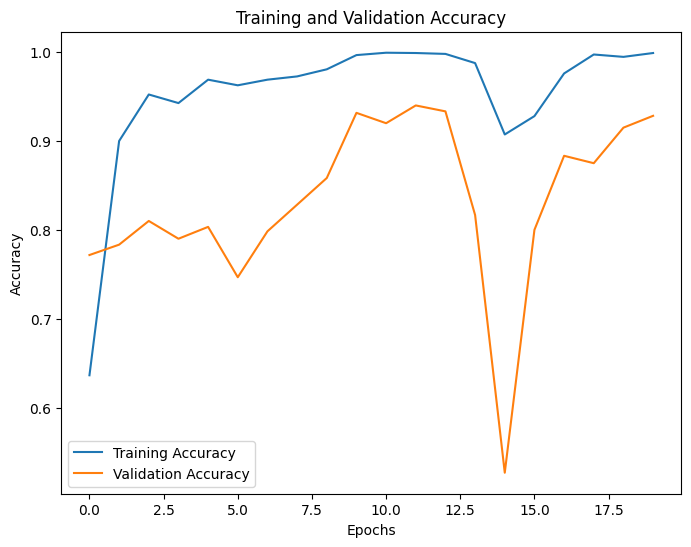

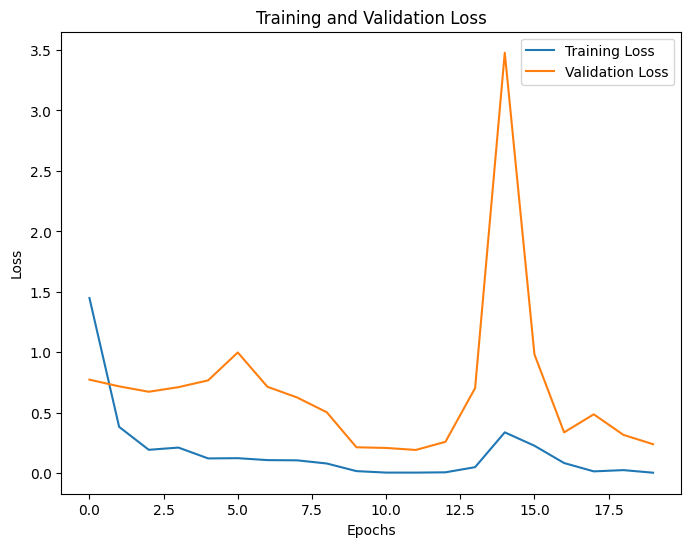

In [10]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 6))
plt.plot(train_acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 6))
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()

In [11]:
# Save the trained model
torch.save(model.state_dict(), "/content/drive/MyDrive/best_resnet_model.pth")

In [38]:
# Test Data
# Function to load and preprocess test images
def load_and_preprocess_images(test_data_path, transform=None):
    image_files = sorted(os.listdir(test_data_path))
    images = []
    for img_file in image_files:
        img_path = os.path.join(test_data_path, img_file)
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        if transform:
            image = transform(image)
        images.append(image)

    return images, image_files
# Load labels from a text file
def load_labels(label_file):
    with open(label_file, "r") as f:
        labels = [int(line.strip()) for line in f.readlines()]
    return labels

Test Data Path: /content/drive/MyDrive/ProjectTask1/val_data
Test Labels Path: /content/drive/MyDrive/ProjectTask1/val_labels.txt


<ipython-input-41-ef96a0fc563b>:41: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("/content/drive/MyDrive/best_resnet_model.pth"))


Test Loss: 0.2407, Test Accuracy: 0.9283


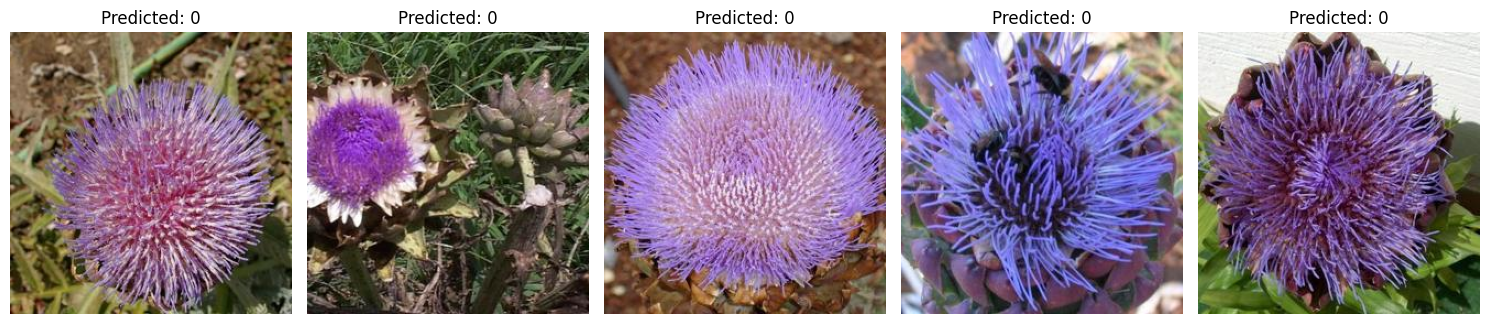

In [41]:
# Test data path (Sir will change this to their directory containing test images)
base_path = "/content/drive/MyDrive/ProjectTask1"
# Define test data path and labels
test_data_path = os.path.join(base_path, "val_data")  #Sir change this to the path of your test images directory
test_labels_path = os.path.join(base_path, "val_labels.txt")  #Sir change this to the path of your test.txt

print(f"Test Data Path: {test_data_path}")
print(f"Test Labels Path: {test_labels_path}")

# Load test labels
test_labels = load_labels(test_labels_path)

# Prepare test dataset and dataloader
test_dataset = FlowerDataset(test_data_path, test_labels, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Evaluate the model on the test dataset
def evaluate_test_data(model, test_loader, criterion):
    model.eval()  # Set the model to evaluation mode
    test_loss, test_correct = 0, 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Calculate metrics
            test_loss += loss.item()
            test_correct += (outputs.argmax(dim=1) == labels).sum().item()

    test_loss /= len(test_loader)
    test_accuracy = test_correct / len(test_dataset)

    print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.4f}")
    return test_loss, test_accuracy

# Load the best trained model for evaluation
model.load_state_dict(torch.load("/content/drive/MyDrive/best_resnet_model.pth"))

# Evaluate the model on the test set
test_loss, test_accuracy = evaluate_test_data(model, test_loader, criterion)

# Display a few test images with predictions
def display_test_predictions(model, test_loader, test_data_path):
    model.eval()  # Ensure the model is in evaluation mode
    test_predictions = []
    test_image_files = sorted(os.listdir(test_data_path))  # Retrieve test image files

    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            test_predictions.extend(preds.cpu().numpy())

    # Visualize predictions for a few test images
    fig, axes = plt.subplots(1, 5, figsize=(15, 5))  # Display 5 test images
    for i, ax in enumerate(axes):
        if i >= len(test_predictions):
            break

        img_path = os.path.join(test_data_path, test_image_files[i])
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        ax.imshow(image)
        ax.set_title(f"Predicted: {test_predictions[i]}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# Display predictions
display_test_predictions(model, test_loader, test_data_path)
